# Regresión Logística — Impacto del diésel en SOBOCE S.A.
**Proyecto de Minería de Datos · Metodología CRISP-DM · Entrega: Modelo de clasificación**

*Integrantes: Wara Jhoseany Callejas Mullisaca · Isabel Belen Castillo Miranda · Arnold Rodrigo Villa Lopez · Abril Michelle Cayllagua Marca · Daniel Gustavo Zambrana Rondon*

---
## 1. Definición del problema y variable objetivo

### Contexto
Tras el DS 5676 (17-ago-2026) el diésel de SOBOCE pasó de Bs 3.75/L (subsidiado) a Bs 18.14/L. En el proyecto definimos como KPI el **Costo del Diésel Operativo por Tonelada producida (CDO_Ton, Bs/Ton)**:

$$CDO\_Ton = \frac{Costo\_Diesel\_Total\_Bs}{Volumen\_Produccion\_Ton}$$

### Variable dependiente (binaria): `ALTO_CDO`
| Valor | Significado |
|---|---|
| **1** | El lote/despacho tiene un CDO_Ton **mayor al percentil 75** histórico (lote *crítico*) |
| **0** | El lote tiene un CDO_Ton normal (≤ P75) |

**¿Por qué esta variable?**
- El objetivo de negocio del proyecto es **evaluar el impacto económico del incremento del precio del diésel en los costos operativos** de SOBOCE (sin proponer soluciones), y el objetivo de datos es analizar la relación entre precio, consumo, producción y costos. Una etiqueta crítico / no crítico permite **caracterizar bajo qué condiciones el costo del combustible por tonelada se dispara** y cuánto pesa el precio frente a los factores operativos.
- Se usa el **percentil 75** y no la meta de 78.5 Bs/Ton del documento porque esa meta sólo la superan ~1% de los registros (clases extremadamente desbalanceadas); con P75 se obtiene una proporción 75 % / 25 %, suficiente para entrenar y evaluar.
- La regresión del CDO_Ton queda para el modelo de regresión (Random Forest/XGBoost) previsto en el documento; aquí abordamos la versión de **clasificación** del mismo problema.

### Variables independientes (explicativas)
| Variable | Justificación |
|---|---|
| `Precio_Diesel_Aplicado_SOBOCE_Bs_Litro` | Captura el shock regulatorio (DS 5516 / DS 5676): es el factor exógeno principal |
| `Distancia_Prom_Transporte_Km` | El transporte es el 71.8 % del diésel total (EDA del documento) |
| `Volumen_Produccion_Ton` | Economías de escala: el costo se reparte entre más toneladas |
| `Horas_Operacion_Maquinaria` | Proxy del consumo de maquinaria de planta/cantera (28.2 %) |
| `Num_Vehiculos_Transporte` | Tamaño de flota asignada al despacho |
| `Planta`, `Region_Destino`, `Tipo_Cemento` (categóricas) | Diferencias estructurales entre plantas, destinos y tipo de producto |

### Variables excluidas deliberadamente
- **Fuga de información (data leakage):** `Consumo_Diesel_*`, `Costo_Diesel_*`, `Costo_Transporte_Bs_Ton`, `Emisiones_CO2_Ton`, `Costo_Produccion_Bs_Ton` y `Margen_Bruto_Pct`. Son componentes del KPI o consecuencias de él; incluirlas haría trivial la predicción.
- **Colinealidad:** `Inflacion_Mensual_Pct`, `Tipo_Cambio_*` y los otros precios de diésel están muy correlacionados con el precio aplicado (se verifica abajo).
- `ID`, `Fecha`, `Pais`, `Empresa` (identificadores o constantes) y `Evento_Regulatorio` / `Categoria_*` (redundantes con el precio).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

# --- Ruta del archivo de datos (ajustar si es necesario) ---
CANDIDATAS = [
    "Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
    "Data/Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "/mnt/user-data/uploads/Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
]
RUTA = next((r for r in CANDIDATAS if os.path.exists(r)), None)
assert RUTA is not None, "No se encontró el archivo .xlsx: súbelo o corrige la lista CANDIDATAS."
print("Archivo de datos:", RUTA)

Archivo de datos: /mnt/user-data/uploads/Impacto_Diesel_Cementera_SOBOCE__2_.xlsx


---
## 2. Preparación de los datos
### 2.1 Carga y construcción de la variable objetivo

In [2]:
df = pd.read_excel(RUTA)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (10000, 31)


,ID,Fecha,Pais,Empresa,Planta,Region_Destino,Tipo_Cemento,Categoria_Consumidor_Diesel,Categoria_Precio_Diesel,Evento_Regulatorio,...,Costo_Diesel_Total_Bs,Costo_Diesel_Total_USD,Costo_Transporte_Bs_Ton,Costo_Produccion_Bs_Ton,Precio_Venta_Cemento_Bs_Bolsa50kg,Margen_Bruto_Pct,Emisiones_CO2_Ton,Num_Vehiculos_Transporte,Horas_Operacion_Maquinaria,Inflacion_Mensual_Pct
0,1,2017-07-13,Bolivia,SOBOCE S.A.,Viacha (La Paz),Oruro,HE (Alta Resistencia),Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,51793.33,7441.57,10.92,450.45,63.20,64.36,37.01,93,18.9,0.21
1,2,2017-07-13,Bolivia,SOBOCE S.A.,El Puente (Tarija),Santa Cruz,HE (Alta Resistencia),Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,63913.17,9182.93,17.29,441.67,63.15,65.03,45.68,97,17.0,0.35
2,3,2017-07-13,Bolivia,SOBOCE S.A.,Warnes (Santa Cruz),Chuquisaca,IP-30,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,75933.98,10910.05,20.54,448.23,61.50,63.56,54.12,92,18.3,0.57
3,4,2017-07-14,Bolivia,SOBOCE S.A.,Viacha (La Paz),Chuquisaca,IP-40,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,37749.28,5423.75,9.59,444.42,59.98,62.95,26.98,82,18.4,0.68
4,5,2017-07-14,Bolivia,SOBOCE S.A.,El Puente (Tarija),Oruro,IP-30,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,52682.25,7569.29,14.53,432.76,63.54,65.94,37.55,85,18.4,0.69


In [3]:
# KPI del proyecto (Entrega 3): Costo del Diésel Operativo por Tonelada (CDO_Ton), en Bs/Ton
df["CDO_Ton"] = df["Costo_Diesel_Total_Bs"] / df["Volumen_Produccion_Ton"]

# Umbral: percentil 75 de la distribución histórica
UMBRAL = df["CDO_Ton"].quantile(0.75)
df["ALTO_CDO"] = (df["CDO_Ton"] > UMBRAL).astype(int)

print(f"Umbral (percentil 75 de CDO_Ton): {UMBRAL:.2f} Bs/Ton")
print(df["CDO_Ton"].describe().round(2))
print()
print(df["ALTO_CDO"].value_counts().rename({0: "Normal (0)", 1: "Alto CDO (1)"}))
print((df["ALTO_CDO"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

Umbral (percentil 75 de CDO_Ton): 27.85 Bs/Ton
count    10000.00
mean        25.41
std         13.26
min          8.15
25%         17.87
50%         22.20
75%         27.85
max        158.55
Name: CDO_Ton, dtype: float64

ALTO_CDO
Normal (0)      7500
Alto CDO (1)    2500
Name: count, dtype: int64
ALTO_CDO
0    75.0 %
1    25.0 %
Name: proportion, dtype: str


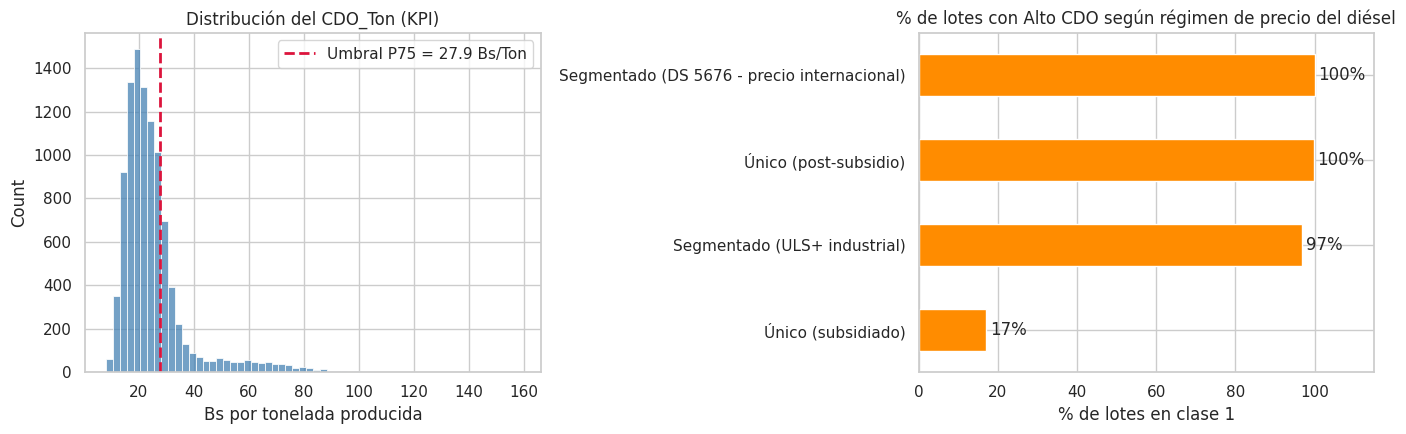

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) Distribución del KPI con el umbral
sns.histplot(df["CDO_Ton"], bins=60, color="steelblue", ax=axes[0])
axes[0].axvline(UMBRAL, color="crimson", ls="--", lw=2, label=f"Umbral P75 = {UMBRAL:.1f} Bs/Ton")
axes[0].set_title("Distribución del CDO_Ton (KPI)")
axes[0].set_xlabel("Bs por tonelada producida"); axes[0].legend()

# (b) % de lotes con Alto CDO por régimen tarifario
tab = (df.groupby("Categoria_Precio_Diesel")["ALTO_CDO"].mean() * 100).sort_values()
tab.plot(kind="barh", color="darkorange", ax=axes[1])
axes[1].set_title("% de lotes con Alto CDO según régimen de precio del diésel")
axes[1].set_xlabel("% de lotes en clase 1")
axes[1].set_ylabel("")
for i, v in enumerate(tab.values):
    axes[1].text(v + 1, i, f"{v:.0f}%", va="center")
axes[1].set_xlim(0, 115)
plt.tight_layout(); plt.show()

**Interpretación.** El umbral P75 es ≈ **27.85 Bs/Ton** y deja 2,500 lotes críticos (25 %) frente a 7,500 normales. La distribución del KPI tiene una cola derecha larga (hasta ~158 Bs/Ton) que corresponde al período posterior al subsidio.

El gráfico de la derecha anticipa el hallazgo central: **el 100 % de los lotes con precios post-subsidio (DS 5516, ULS+ y DS 5676) son críticos**, mientras que bajo el subsidio sólo lo son ~17 %. Es decir, el precio explica gran parte del problema; el resto lo explican las rutas largas.

### 2.2 Selección de variables y revisión de colinealidad

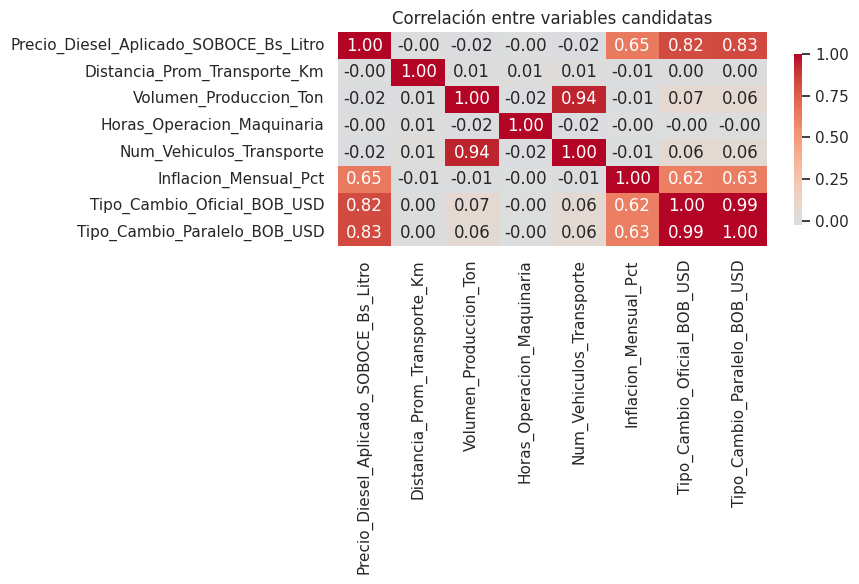

In [5]:
# Variables independientes elegidas
NUM = [
    "Precio_Diesel_Aplicado_SOBOCE_Bs_Litro",  # shock de precios (DS 5516 / DS 5676)
    "Distancia_Prom_Transporte_Km",            # logística (71.8% del diésel)
    "Volumen_Produccion_Ton",                  # economía de escala
    "Horas_Operacion_Maquinaria",              # maquinaria de planta/cantera (28.2%)
    "Num_Vehiculos_Transporte",                # tamaño de flota
]
CAT = ["Planta", "Region_Destino", "Tipo_Cemento"]

X = df[NUM + CAT].copy()
y = df["ALTO_CDO"].copy()

# Revisión de colinealidad entre candidatas numéricas (incluyendo las que se descartaron)
candidatas = NUM + ["Inflacion_Mensual_Pct", "Tipo_Cambio_Oficial_BOB_USD", "Tipo_Cambio_Paralelo_BOB_USD"]
plt.figure(figsize=(9, 6))
sns.heatmap(df[candidatas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": .8})
plt.title("Correlación entre variables candidatas")
plt.tight_layout(); plt.show()

**Interpretación.** Las variables operativas elegidas son prácticamente independientes entre sí (correlaciones cercanas a 0), lo cual es deseable en regresión logística porque los coeficientes son estables e interpretables. En cambio, `Inflacion_Mensual_Pct` y los tipos de cambio están fuertemente asociados al precio del diésel (la inflación y el tipo de cambio suben en el mismo período que el shock), por eso **se excluyen** y se deja el precio aplicado como única medida del shock.

### 2.3 Limpieza de nulos y duplicados

In [6]:
print("Nulos por variable seleccionada:")
print(X.isna().sum())
print("\nNulos en la variable objetivo:", y.isna().sum())
print("Filas duplicadas en el dataset:", df.duplicated().sum())

# Limpieza: eliminar filas con nulos (en este dataset no se espera ninguna) y duplicados
antes = len(df)
mask = X.notna().all(axis=1) & y.notna()
X, y = X[mask], y[mask]
print(f"\nFilas antes: {antes} | después de la limpieza: {len(X)}")

# Chequeo de rangos plausibles / valores atípicos extremos
X[NUM].describe().round(2)

Nulos por variable seleccionada:
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro    0
Distancia_Prom_Transporte_Km              0
Volumen_Produccion_Ton                    0
Horas_Operacion_Maquinaria                0
Num_Vehiculos_Transporte                  0
Planta                                    0
Region_Destino                            0
Tipo_Cemento                              0
dtype: int64

Nulos en la variable objetivo: 0
Filas duplicadas en el dataset: 0

Filas antes: 10000 | después de la limpieza: 10000


,Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,Distancia_Prom_Transporte_Km,Volumen_Produccion_Ton,Horas_Operacion_Maquinaria,Num_Vehiculos_Transporte
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,4.35,136.72,2568.89,18.00,83.08
std,1.89,50.13,324.03,2.54,11.17
min,3.70,20.00,1500.80,8.90,48.00
25%,3.74,98.10,2333.50,16.30,75.00
50%,3.75,131.55,2572.70,18.00,83.00
75%,3.76,172.00,2796.22,19.70,91.00
max,18.43,334.70,3834.90,27.50,135.00


**Interpretación.** El dataset llega **sin valores nulos ni duplicados**, por lo que no se elimina ni imputa ninguna fila (10,000 → 10,000). Los rangos son plausibles (p. ej. distancia 20–335 km, precio 3.70–18.43 Bs/L).
> Si en otro conjunto aparecieran nulos, el código ya filtra filas incompletas; para producción podría usarse imputación (`SimpleImputer`).

### 2.4 División en entrenamiento y prueba (80 / 20)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")
print("\nProporción de la clase 1 (Alto CDO):")
print(f"  Total: {y.mean():.3f} | Train: {y_train.mean():.3f} | Test: {y_test.mean():.3f}")

Entrenamiento: 8000 filas | Prueba: 2000 filas

Proporción de la clase 1 (Alto CDO):
  Total: 0.250 | Train: 0.250 | Test: 0.250


**Interpretación.** Se separa 80 % para entrenar (8,000 filas) y 20 % para evaluar (2,000). Se usa `stratify=y` para que ambos conjuntos conserven la proporción 25 % de lotes críticos, y `random_state=42` para que los resultados sean reproducibles.

---
## 3. Entrenamiento del modelo de regresión logística
### 3.1 Ajuste inicial (modelo base)
La **codificación de variables categóricas** (One-Hot con `drop='first'`) y el **escalado** de las numéricas se hacen dentro de un `Pipeline`, de modo que se aprenden sólo con los datos de entrenamiento (evita fuga de información en la validación cruzada).

In [8]:
# Estandarización de numéricas + One-Hot de categóricas (drop='first' evita la trampa de variables dummy)
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
])

# El preprocesador se ajusta SOLO con train dentro del pipeline (evita fuga de información)
modelo_base = Pipeline([
    ("prep", preprocesador),
    ("logreg", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
modelo_base.fit(X_train, y_train)

nombres = modelo_base.named_steps["prep"].get_feature_names_out()
print(f"Variables tras la codificación: {len(nombres)}")
print("Accuracy train:", round(modelo_base.score(X_train, y_train), 4))
print("Accuracy test :", round(modelo_base.score(X_test, y_test), 4))

Variables tras la codificación: 16
Accuracy train: 0.9519
Accuracy test : 0.9435


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for metrica in ["accuracy", "f1", "roc_auc"]:
    s = cross_val_score(modelo_base, X_train, y_train, cv=cv, scoring=metrica)
    print(f"{metrica:9s}: {s.mean():.4f} ± {s.std():.4f}")

accuracy : 0.9501 ± 0.0037


f1       : 0.8987 ± 0.0074


roc_auc  : 0.9914 ± 0.0009


**Interpretación.** Tras la codificación quedan 16 variables. El modelo base alcanza ≈ 95.2 % de accuracy en entrenamiento y ≈ 94.4 % en prueba: la diferencia es pequeña, **no hay sobreajuste**. La validación cruzada de 5 pliegues confirma estabilidad (accuracy 0.950 ± 0.004, F1 0.899 ± 0.007 y AUC 0.991 ± 0.001).

### 3.2 Validación y ajuste de hiperparámetros (GridSearchCV)
Se prueba la fuerza de regularización `C`, el tipo de penalización (L1 / L2) y el balanceo de clases, optimizando **F1** con validación cruzada estratificada de 5 pliegues.

In [10]:
pipe = Pipeline([
    ("prep", preprocesador),
    ("logreg", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)),
])

param_grid = {
    "logreg__C": [0.01, 0.1, 1, 10, 100],          # inverso de la regularización
    "logreg__penalty": ["l1", "l2"],                # Lasso vs Ridge
    "logreg__class_weight": [None, "balanced"],     # manejo del desbalance 75/25
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor F1 en validación cruzada: {grid.best_score_:.4f}")

resultados = (pd.DataFrame(grid.cv_results_)
              [["param_logreg__C", "param_logreg__penalty", "param_logreg__class_weight", "mean_test_score", "std_test_score"]]
              .sort_values("mean_test_score", ascending=False).head(8).round(4))
resultados

Mejores hiperparámetros: {'logreg__C': 10, 'logreg__class_weight': None, 'logreg__penalty': 'l1'}
Mejor F1 en validación cruzada: 0.9011


,param_logreg__C,param_logreg__penalty,param_logreg__class_weight,mean_test_score,std_test_score
12,10.0,l1,NaN,0.9011,0.0087
16,100.0,l1,NaN,0.9009,0.0084
17,100.0,l2,NaN,0.9009,0.0084
15,10.0,l2,balanced,0.9004,0.0113
18,100.0,l1,balanced,0.9004,0.0108
6,0.1,l1,balanced,0.9004,0.0089
10,1.0,l1,balanced,0.9002,0.0100
14,10.0,l1,balanced,0.9002,0.0112


**Interpretación.** La mejor configuración fue `C = 10`, penalización **L1** y sin ponderar clases (F1 CV ≈ 0.901). Las ocho mejores combinaciones difieren menos de 0.001 en F1, es decir, **el modelo es poco sensible a los hiperparámetros**: el problema es casi linealmente separable y la regularización aporta poco. La penalización L1 es útil porque tiende a reducir a cero los coeficientes irrelevantes (selección de variables).

---
## 4. Evaluación del modelo
### 4.1 Métricas de clasificación
Se compara el modelo base con el ajustado, en entrenamiento y en prueba.

In [11]:
modelo = grid.best_estimator_

def metricas(nombre, mdl, X_, y_):
    pred = mdl.predict(X_)
    proba = mdl.predict_proba(X_)[:, 1]
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

tabla = pd.DataFrame([
    metricas("Base (train)", modelo_base, X_train, y_train),
    metricas("Base (test)", modelo_base, X_test, y_test),
    metricas("Ajustado (train)", modelo, X_train, y_train),
    metricas("Ajustado (test)", modelo, X_test, y_test),
]).set_index("Modelo").round(4)
tabla

,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Base (train),0.9519,0.9147,0.8905,0.9025,0.9918
Base (test),0.9435,0.8941,0.8780,0.8860,0.9893
Ajustado (train),0.9518,0.9130,0.8920,0.9024,0.9918
Ajustado (test),0.9430,0.8923,0.8780,0.8851,0.9892


In [12]:
y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Alto CDO (1)"], digits=3))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos (TN): {tn}\nFalsos positivos  (FP): {fp}\nFalsos negativos  (FN): {fn}\nVerdaderos positivos (TP): {tp}")

              precision    recall  f1-score   support

  Normal (0)      0.960     0.965     0.962      1500
Alto CDO (1)      0.892     0.878     0.885       500

    accuracy                          0.943      2000
   macro avg      0.926     0.921     0.924      2000
weighted avg      0.943     0.943     0.943      2000

Verdaderos negativos (TN): 1447
Falsos positivos  (FP): 53
Falsos negativos  (FN): 61
Verdaderos positivos (TP): 439


**Interpretación de las métricas (conjunto de prueba, 2,000 lotes):**

- **Accuracy 94.3 %:** de cada 100 lotes, ~94 se clasifican correctamente. Como la clase 1 es sólo el 25 %, un modelo que dijera siempre «normal» tendría 75 %; estamos 19 puntos por encima.
- **Precision 0.89:** cuando el modelo marca un lote como *crítico*, acierta el 89 % de las veces → pocas «falsas alarmas» (53 lotes).
- **Recall 0.88:** detecta el 88 % de los lotes realmente críticos; se escapan 61 (falsos negativos).
- **F1 0.885:** equilibrio entre ambos.
- **Matriz de confusión:** TN = 1447, FP = 53, FN = 61, TP = 439.

**Lectura para el negocio:** un falso negativo es un lote costoso que el análisis no identifica; un falso positivo es revisar un lote que no era crítico (costo bajo). Por eso puede convenir priorizar el *recall* — se analiza en 5.3.

**Base vs. ajustado:** el ajuste de hiperparámetros **no mejora** el resultado en prueba (F1 0.886 vs 0.885; diferencia sin relevancia). Esto es un resultado válido: el modelo base ya era adecuado, y se conserva el ajustado por su regularización L1, más parsimoniosa. Train y test son muy similares, descartando sobreajuste.

---
## 5. Visualización y comunicación
### 5.1 Matriz de confusión y curva ROC

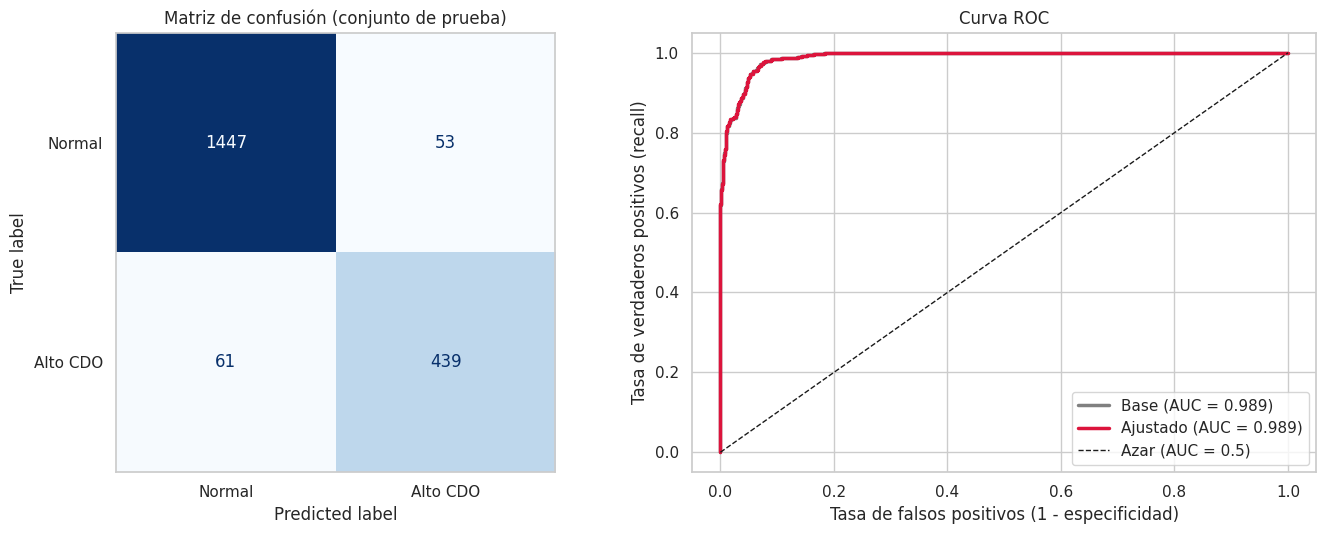

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Matriz de confusión
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Alto CDO"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Matriz de confusión (conjunto de prueba)")
axes[0].grid(False)

# Curva ROC: modelo base vs ajustado
for nombre, mdl, color in [("Base", modelo_base, "gray"), ("Ajustado", modelo, "crimson")]:
    fpr, tpr, _ = roc_curve(y_test, mdl.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, color=color, lw=2.5, label=f"{nombre} (AUC = {roc_auc_score(y_test, mdl.predict_proba(X_test)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
axes[1].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[1].set_title("Curva ROC"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretación.** La **curva ROC** se pega a la esquina superior izquierda con un **AUC ≈ 0.989**: si se toma al azar un lote crítico y uno normal, el modelo asigna mayor probabilidad al crítico el 98.9 % de las veces. El AUC es una medida de la capacidad de *ordenar* lotes por riesgo, independiente del umbral. Las curvas de los modelos base y ajustado casi se superponen, coherente con la tabla anterior. En la matriz de confusión la diagonal domina: los errores son pocos y están balanceados entre falsos positivos y falsos negativos.

### 5.2 ¿Qué variables explican un lote crítico? (coeficientes)
Los coeficientes están en escala de *log-odds* con variables numéricas estandarizadas; el `odds_ratio` indica cuánto se multiplican las probabilidades (odds) de ser crítico por **1 desviación estándar** de aumento (o por pertenecer a la categoría, frente a la categoría de referencia).

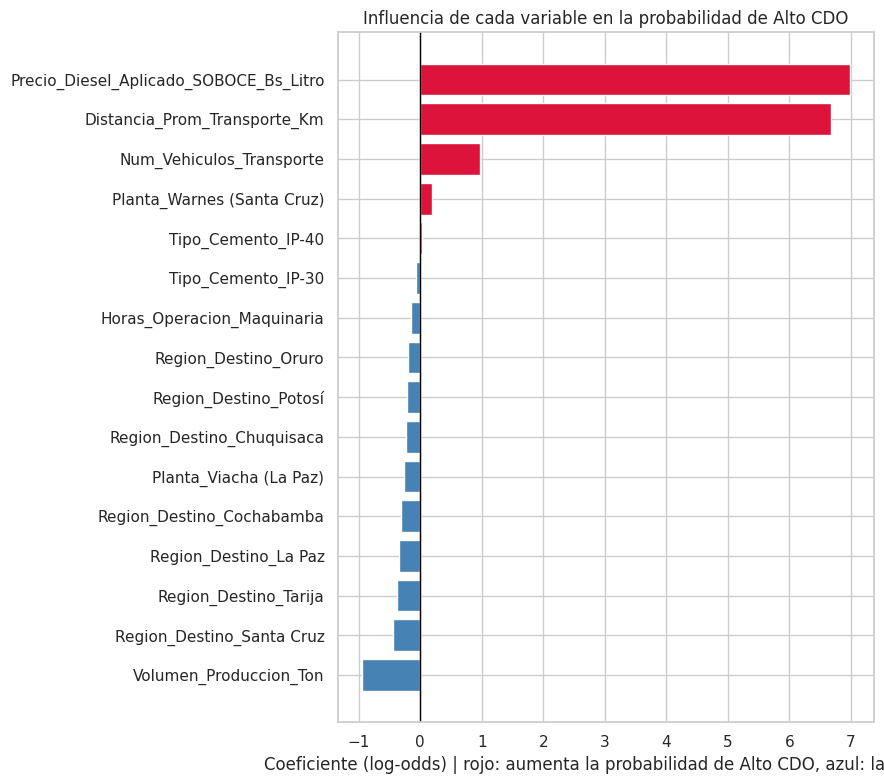

,variable,coef,odds_ratio
0,Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,6.977,1071.877
1,Distancia_Prom_Transporte_Km,6.679,795.789
2,Num_Vehiculos_Transporte,0.973,2.645
3,Planta_Warnes (Santa Cruz),0.189,1.208
4,Tipo_Cemento_IP-40,0.031,1.031
5,Tipo_Cemento_IP-30,-0.061,0.941
6,Horas_Operacion_Maquinaria,-0.151,0.860
7,Region_Destino_Oruro,-0.205,0.815
8,Region_Destino_Potosí,-0.211,0.810
9,Region_Destino_Chuquisaca,-0.233,0.792


In [14]:
nombres = modelo.named_steps["prep"].get_feature_names_out()
coefs = modelo.named_steps["logreg"].coef_[0]
imp = (pd.DataFrame({"variable": [n.split("__")[1] for n in nombres], "coef": coefs})
       .assign(odds_ratio=lambda d: np.exp(d["coef"]))
       .sort_values("coef"))

colors = ["crimson" if c > 0 else "steelblue" for c in imp["coef"]]
plt.figure(figsize=(9, 8))
plt.barh(imp["variable"], imp["coef"], color=colors)
plt.axvline(0, color="black", lw=1)
plt.xlabel("Coeficiente (log-odds) | rojo: aumenta la probabilidad de Alto CDO, azul: la reduce")
plt.title("Influencia de cada variable en la probabilidad de Alto CDO")
plt.tight_layout(); plt.show()

imp.sort_values("coef", ascending=False).round(3).reset_index(drop=True)

**Interpretación — hallazgos para la gerencia:**

1. **Precio del diésel** (coef. ≈ +7.0) y **distancia de transporte** (≈ +6.7) son, por lejos, los dos determinantes. El primero es exógeno (regulación) y el segundo operativo: el modelo **cuantifica que el shock de precio y las rutas largas son los dos factores que más elevan el costo del combustible por tonelada**.
2. **Volumen de producción** tiene efecto protector (≈ −0.95): mayor volumen diluye el costo por tonelada (economías de escala).
3. **Número de vehículos** aumenta el riesgo (≈ +0.97): más camiones por lote se asocia a un mayor costo por tonelada.
4. Planta, destino y tipo de cemento tienen efectos pequeños una vez controlada la distancia (sus coeficientes están entre −0.45 y +0.19); el tipo de cemento es prácticamente irrelevante.

> **Precaución:** los *odds ratios* de precio y distancia son enormes porque ambas variables separan casi perfectamente las clases; deben leerse como «efecto dominante», no como cifras exactas. Además, las magnitudes dependen del umbral P75 elegido.

### 5.3 Umbral de decisión: ¿precisión o recall?

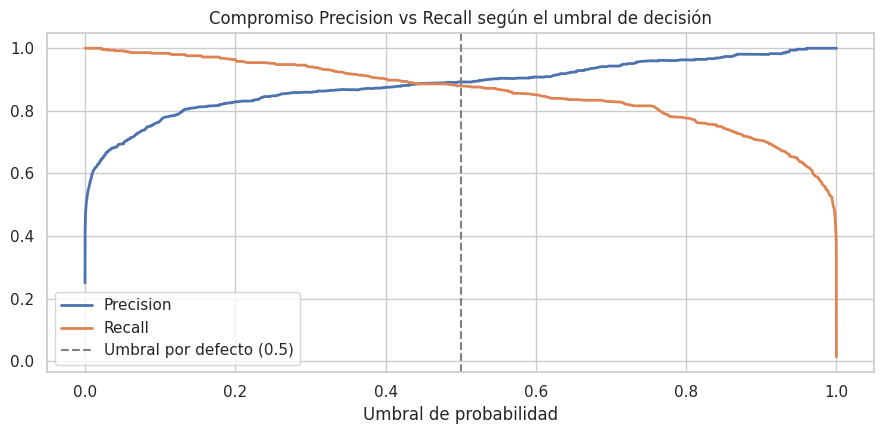

Umbral 0.3: precision=0.859 | recall=0.940 | F1=0.898
Umbral 0.4: precision=0.876 | recall=0.902 | F1=0.889
Umbral 0.5: precision=0.892 | recall=0.878 | F1=0.885
Umbral 0.6: precision=0.908 | recall=0.850 | F1=0.878


In [15]:
prec, rec, thr = precision_recall_curve(y_test, y_proba)
plt.figure(figsize=(9, 4.5))
plt.plot(thr, prec[:-1], label="Precision", lw=2)
plt.plot(thr, rec[:-1], label="Recall", lw=2)
plt.axvline(0.5, color="gray", ls="--", label="Umbral por defecto (0.5)")
plt.xlabel("Umbral de probabilidad"); plt.title("Compromiso Precision vs Recall según el umbral de decisión")
plt.legend(); plt.tight_layout(); plt.show()

for t in [0.3, 0.4, 0.5, 0.6]:
    p = (y_proba >= t).astype(int)
    print(f"Umbral {t}: precision={precision_score(y_test, p):.3f} | recall={recall_score(y_test, p):.3f} | F1={f1_score(y_test, p):.3f}")

**Interpretación.** El umbral por defecto (0.5) equilibra precisión y recall. Si el costo de **no detectar** un lote crítico es mayor que el de revisar un lote de más, conviene **bajar el umbral a ≈ 0.3**: el recall sube de 0.878 a 0.940 (se detectan 31 lotes críticos adicionales de cada 500) a cambio de bajar la precisión de 0.892 a 0.859, y el F1 incluso mejora levemente (0.898). Es una decisión de negocio, no estadística.

### 5.4 Análisis de errores por régimen de precio

In [16]:
# ¿Dónde se equivoca el modelo? Desempeño por régimen tarifario (conjunto de prueba)
an = X_test.copy()
an["real"] = y_test.values; an["pred"] = y_pred
an["Regimen"] = df.loc[X_test.index, "Categoria_Precio_Diesel"].values
an["error"] = (an["real"] != an["pred"]).astype(int)
resumen = an.groupby("Regimen").agg(lotes=("real", "size"), alto_cdo_real=("real", "mean"),
                                    tasa_error=("error", "mean")).round(3)
resumen

,lotes,alto_cdo_real,tasa_error
Regimen,,,
Segmentado (DS 5676 - precio internacional),7,1.000,0.000
Segmentado (ULS+ industrial),39,1.000,0.000
Único (post-subsidio),148,1.000,0.000
Único (subsidiado),1806,0.169,0.063


**Interpretación.** El modelo **no comete ningún error en los lotes posteriores al subsidio** (194 lotes, todos críticos y todos bien clasificados): con precios de Bs 8.8–18.1/L el costo por tonelada supera el umbral sin importar la ruta. **Todos los errores (6.3 % de tasa) ocurren en el período subsidiado**, donde la distinción entre crítico y normal depende de la distancia y del volumen — allí el modelo tiene que decidir en la «zona frontera» del umbral.

---
## 6. Escenarios de mitigación del alza del diésel
El modelo logístico identificó **qué factores elevan el costo**; ahora se usan para **simular medidas de mitigación** sobre los lotes bajo el DS 5676 (baseline ≈ 102.85 Bs/Ton, según el documento de Fase 1). Se calcula directamente el KPI `CDO_Ton` en cada escenario:

| Escenario | Medida | Base del supuesto |
|---|---|---|
| **A** | 25 % de la flota de transporte migra a GNV/GNL | % del documento de Fase 1; costo del GNV = 50 % del diésel (**supuesto**) |
| **B** | Optimización de rutas: −10 % de distancia media | **supuesto**; el diésel de transporte es casi proporcional a la distancia (correlación ≈ 0.94) |
| **C** | Mayor factor de carga: −5 % del diésel de transporte | **supuesto**; coherente con el efecto protector del volumen |
| **A+B+C** | Combinación de las tres | — |

> ⚠️ Los parámetros de costo del GNV y los porcentajes de mejora **no están en la base de datos**: son hipótesis a reemplazar por cotizaciones y datos reales de SOBOCE. Están al inicio de la celda para modificarlos fácilmente.

Lotes DS 5676: 34


,CDO_Ton (Bs/Ton),Reducción vs baseline (%),¿Alcanza meta 78.5?
Baseline (DS 5676),102.85,0.00,No
A. 25% flota a GNV/GNL,93.74,8.86,No
B. Rutas -10% distancia,95.56,7.09,No
C. Factor de carga +5%,99.21,3.54,No
A+B+C combinadas,84.50,17.85,No


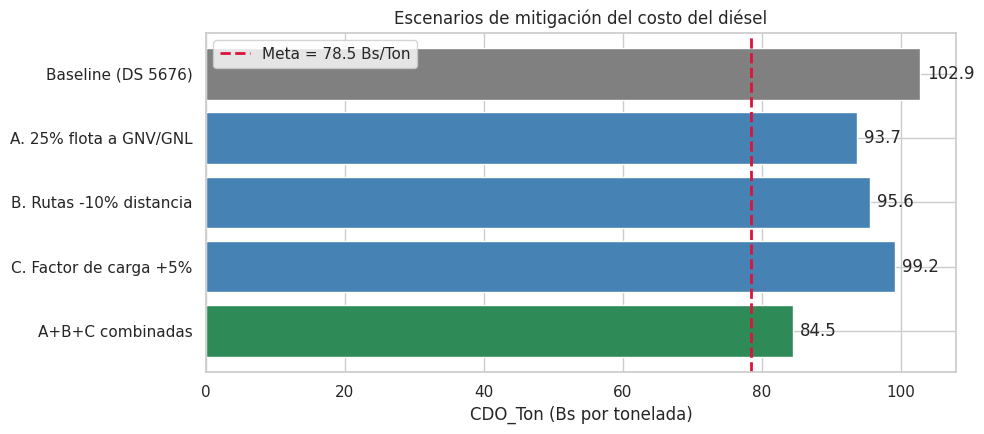

In [17]:
# Punto de partida: lotes bajo el DS 5676 (precio internacional, Bs ~18.14/L)
base = df[df["Categoria_Precio_Diesel"].str.contains("DS 5676")].copy()
print(f"Lotes DS 5676: {len(base)}")

def cdo(maq_l, trans_l, precio, vol, trans_costo_factor=1.0):
    """CDO_Ton = (diesel maquinaria + diesel transporte * factor de costo) * precio / volumen"""
    return ((maq_l + trans_l * trans_costo_factor) * precio / vol).mean()

maq, tra, p, v = (base["Consumo_Diesel_Maquinaria_L"], base["Consumo_Diesel_Transporte_L"],
                  base["Precio_Diesel_Aplicado_SOBOCE_Bs_Litro"], base["Volumen_Produccion_Ton"])
BASELINE = cdo(maq, tra, p, v)
META = 78.50   # meta cuantitativa del documento de Fase 1

# ---- SUPUESTOS (NO provienen de la base; ajustar con datos reales de SOBOCE) ----
FLOTA_GNV = 0.25      # % del transporte que migra a GNV/GNL (documento Fase 1)
COSTO_GNV = 0.50      # costo por litro-equivalente de GNV como fracción del diésel a Bs 18.14 (supuesto)
RED_DIST = 0.10       # reducción de la distancia media por optimización de rutas (supuesto)
RED_CARGA = 0.05      # reducción del diésel de transporte por mayor factor de carga (supuesto)

esc = {
    "Baseline (DS 5676)": BASELINE,
    "A. 25% flota a GNV/GNL": cdo(maq, tra, p, v, 1 - FLOTA_GNV * (1 - COSTO_GNV)),
    "B. Rutas -10% distancia": cdo(maq, tra * (1 - RED_DIST), p, v),
    "C. Factor de carga +5%": cdo(maq, tra * (1 - RED_CARGA), p, v),
    "A+B+C combinadas": cdo(maq, tra * (1 - RED_DIST) * (1 - RED_CARGA), p, v, 1 - FLOTA_GNV * (1 - COSTO_GNV)),
}
res = pd.DataFrame({"CDO_Ton (Bs/Ton)": esc})
res["Reducción vs baseline (%)"] = (1 - res["CDO_Ton (Bs/Ton)"] / BASELINE) * 100
res["¿Alcanza meta 78.5?"] = np.where(res["CDO_Ton (Bs/Ton)"] <= META, "Sí", "No")
display(res.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["gray"] + ["steelblue"] * 3 + ["seagreen"]
ax.barh(res.index[::-1], res["CDO_Ton (Bs/Ton)"][::-1], color=colores[::-1])
ax.axvline(META, color="crimson", ls="--", lw=2, label=f"Meta = {META} Bs/Ton")
for i, v_ in enumerate(res["CDO_Ton (Bs/Ton)"][::-1]):
    ax.text(v_ + 1, i, f"{v_:.1f}", va="center")
ax.set_xlabel("CDO_Ton (Bs por tonelada)"); ax.set_title("Escenarios de mitigación del costo del diésel"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación.**
- Ninguna medida por sí sola alcanza la meta de 78.5 Bs/Ton: la sustitución del 25 % de la flota baja el KPI ≈ 8.9 % (a ≈ 93.7), las rutas −10 % ≈ 7.1 % (≈ 95.6) y el factor de carga ≈ 3.5 % (≈ 99.2).
- **Combinadas** llegan a ≈ **84.5 Bs/Ton (−17.8 %)**: es la mejor opción, pero todavía queda ≈ 6 Bs/Ton por encima de la meta (la meta pedía −23.7 %).
- Cada medida solo actúa sobre el transporte (≈ 71 % del diésel); la maquinaria de planta, que sigue pagando Bs 18/L, no se toca. Para cerrar la brecha haría falta ampliar la sustitución o actuar también sobre planta/cantera (p. ej. petcoke/biomasa, como el caso Holcim/Argos del documento).

### Sensibilidad de la sustitución a GNV/GNL

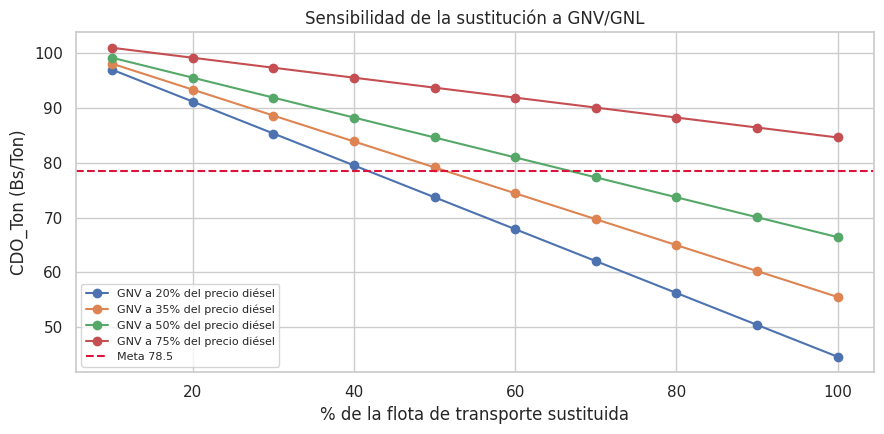

In [18]:
# Sensibilidad: ¿qué tan barato debe ser el GNV para que la sustitución sola alcance la meta?
fracciones = np.linspace(0.1, 1.0, 10)
costos = [0.2, 0.35, 0.5, 0.75]
tabla = pd.DataFrame({f"GNV a {int(c*100)}% del precio diésel":
    [cdo(maq, tra, p, v, 1 - f * (1 - c)) for f in fracciones] for c in costos},
    index=[f"{int(f*100)}% flota" for f in fracciones])
plt.figure(figsize=(9, 4.5))
for col in tabla.columns: plt.plot(fracciones * 100, tabla[col], marker="o", label=col)
plt.axhline(META, color="crimson", ls="--", label="Meta 78.5")
plt.xlabel("% de la flota de transporte sustituida"); plt.ylabel("CDO_Ton (Bs/Ton)")
plt.title("Sensibilidad de la sustitución a GNV/GNL"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.** El ahorro depende mucho de **qué tan barato sea el GNV** y de **cuánta flota se convierta**. Con el GNV a 50 % del precio del diésel, sustituir el **100 %** del transporte llevaría el KPI a ≈ 66 Bs/Ton (bajo la meta), y con 75 % del precio apenas a ≈ 85. Antes de decidir la inversión, el dato crítico a conseguir es el **costo real por litro-equivalente de GNV/GNL** y el costo de conversión de los camiones, que no están en la base.

---
## 7. Conclusiones, limitaciones y siguientes pasos

**Conclusiones**
- Un modelo de regresión logística **simple e interpretable** clasifica correctamente el 94 % de los lotes (F1 = 0.885, AUC = 0.989) y no presenta sobreajuste.
- **Precio del diésel y distancia de transporte** explican casi todo el riesgo de un lote crítico; mayor volumen lo reduce. Esto es coherente con el EDA del proyecto, donde la **logística de distribución** concentra el 71.8 % del consumo de diésel.
- Con precios post-subsidio **todos** los lotes pasan a ser críticos; por tanto, el umbral P75 histórico deja de discriminar en el nuevo escenario: el impacto del decreto se manifiesta como un **desplazamiento de todo el nivel del CDO_Ton**, no sólo de algunos lotes.

**Limitaciones**
- Los datos son **sintéticos** (así lo indica la ficha técnica); los resultados reflejan las reglas con que se generaron y podrían ser más optimistas que con datos reales.
- Sólo ~1,000 registros (10 %) son del régimen post-subsidio; la división aleatoria mezcla períodos. Una validación **temporal** (entrenar con el pasado, probar con lo reciente) sería más exigente.
- Inconsistencia detectada: el documento de la Entrega 3 reporta **341** registros bajo el DS 5676, pero en la base hay **34** (la categoría «Segmentado (DS 5676)»); conviene corregirlo en el documento.
- La definición de «crítico» (P75) es una decisión de negocio; con otro umbral cambiarían las métricas.

**Mitigación:** los escenarios de la sección 6 muestran que una combinación de GNV/GNL, rutas y carga reduce el KPI ≈ 18 % pero no alcanza la meta de −23.7 %; los resultados dependen de supuestos que deben validarse con datos reales. *(Nota: la presentación del proyecto declara el alcance como evaluación del impacto; la sección 6 sigue el documento de Fase 1, que sí incluye la estrategia de mitigación; el grupo puede omitirla si prefiere ceñirse al alcance de la presentación.)* **Siguientes pasos** (según el documento de Fase 1): modelo de regresión del CDO_Ton y clustering de rutas.